# Experimento 7 — Idade, ano e contagens: a receita final

**De onde viemos.** A síntese (notebook 09) consolidou a referência de seis colunas (duas médias, afinidade, afinidade² e dois indicadores de gênero; regressão com RMSE 0,625036) e encontrou estrutura restante nos resíduos por **idade** e por **ano de lançamento**. Ela propôs testar essas duas variáveis, uma alteração por vez.

**Hipóteses**
1. Idade e ano de lançamento acrescentam informação. O arco nos resíduos por ano sugere testar um termo linear e depois um quadrático.
2. As duas contagens (`user_n_ratings`, `movie_n_ratings`), em `log(1 + n)`, acrescentam informação sobre a confiabilidade das médias.
3. Com a melhor representação, regressão, Ridge e boosting são comparados de novo, com informação igual.

Este notebook documenta os testes que levaram à **receita final** (boosting com onze colunas) e à submissão. O código vem de `src/final_feature_tests.py`, `src/count_feature_test.py`, `src/ridge_sensitivity.py` e `src/final_submission.py`. Aqui reutilizamos as mesmas funções, para que os números sejam os mesmos dos scripts.

**Protocolo:** 5 dobras × 5 repetições, semente 2026; mesmas partições dos experimentos 03–08, apenas `train.csv`, previsões cortadas em [0, 5]. Ridge e boosting escolhem hiperparâmetros em 3 dobras internas de cada treino externo.

O RMSE considera as cinco previsões fora da dobra (OOF) de cada linha separadamente. As partições compartilham treino: desvios e vitórias são descritivos. Para comparar dois modelos usamos o teste t corrigido de Nadeau e Bengio (`src/corrected_test.py`). As hipóteses vieram da exploração destes dados; não são confirmação independente.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import RepeatedKFold

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data' / 'train.csv').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.corrected_test import corrected_paired_ttest
from src.count_feature_test import COUNT_FEATURES
from src.final_feature_tests import FEATURE_SETS, compare_procedures, evaluate_feature_sets, prepare
from src.final_submission import BASE_FEATURES, NINE_FEATURES, clipped_rmse
from src.ridge_sensitivity import ALPHAS, model_for

N_SPLITS = 5
N_REPEATS = 5
SEED = 2026
CLIP = True
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
# O BLAS do macOS emite avisos espúrios de overflow no produto matricial; os resultados não são afetados.
warnings.filterwarnings('ignore', category=RuntimeWarning)

df = prepare(pd.read_csv(ROOT / 'data' / 'train.csv'))
df['log_user_n_ratings'] = np.log1p(df['user_n_ratings'])
df['log_movie_n_ratings'] = np.log1p(df['movie_n_ratings'])
y = df['stars'].to_numpy(dtype=float)
folds = list(RepeatedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED).split(df))
print(df.shape, len(folds), 'partições')

(4000, 20) 25 partições


### As colunas novas

| Coluna | Definição | Por quê |
|---|---|---|
| `age` | idade, sem transformação | resíduos por idade na síntese 09 |
| `release_year_scaled` | (ano − 2000) / 10 | centro e escala **fixos**, que não aprendem nada com os dados (sem vazamento) |
| `release_year_squared` | quadrado da coluna anterior | o arco nos resíduos por ano pede uma curva |
| `log_user_n_ratings`, `log_movie_n_ratings` | log(1 + n) | as contagens têm cauda longa; o log reduz a assimetria |

Contamos **colunas construídas**, não atributos brutos: 6 na referência, 9 com idade e ano, 11 com as contagens. A receita final usa a informação dos **dez atributos brutos**: gênero e proporções viram afinidade e indicadores, e o ano vira dois termos.

## 1. Idade e ano na regressão

Acrescentamos uma coisa por vez à referência de seis colunas e avaliamos com regressão sem penalização. A regressão é rápida e mostra se a informação ajuda numa forma simples.

In [2]:
feature_result, _ = evaluate_feature_sets(df, y, folds)
display(feature_result.round(6))

,modelo,n_atributos,RMSE OOF repetido,RMSE validação médio,desvio entre partições,RMSE treino médio
5,"+ idade, ano linear e quadrático",9,0.616080,0.615905,0.015010,0.613627
4,+ idade e ano linear,8,0.618458,0.618283,0.015026,0.616273
3,+ ano linear e quadrático,8,0.620512,0.620339,0.014961,0.618420
1,+ idade,7,0.620722,0.620553,0.014770,0.618712
2,+ ano linear,7,0.622705,0.622534,0.014895,0.620879
0,Referência (6 atributos),6,0.625036,0.624868,0.014793,0.623377


**Leitura**
- Cada acréscimo ajuda um pouco: idade sozinha leva de 0,625 a 0,621, e o termo quadrático do ano ajuda mais quando usado junto com a idade.
- O melhor conjunto (idade + ano + ano², **nove colunas**) chega a 0,616. O ganho na regressão é **pequeno**, cerca de 0,009.
- A distância entre treino e validação continua mínima (cerca de 0,002): o modelo linear tem baixa variância.

## 2. Com nove colunas: regressão, Ridge e boosting

Com o melhor conjunto fixado, repetimos a comparação de procedimentos do experimento 5, agora com **informação igual** de nove colunas. Ridge escolhe `alpha` e o boosting escolhe a grade do notebook 07, ambos em 3 dobras internas.

Esta célula ajusta 600 boostings internos por comparação e demora alguns minutos.

In [3]:
summary_9, by_fold_9, selections_9, predictions_9 = compare_procedures(df, y, folds, NINE_FEATURES)
display(summary_9.round(6))

,modelo,RMSE OOF repetido,RMSE_validação_médio,desvio_partições,RMSE_treino_médio
0,Regressão comum,0.616080,0.615905,0.015010,0.613627
1,Ridge,0.616081,0.615905,0.015009,0.613628
2,Boosting,0.565157,0.565014,0.012994,0.455727


**Leitura:** a mesma informação que melhorou a regressão em 0,009 melhora o boosting em cerca de **0,054** (0,619 no experimento 5 → 0,565). Idade e ano parecem agir principalmente por meio de **interações** ou formas que a regressão aditiva não representa. O experimento 8 (notebook 12) investiga qual é essa interação.

## 3. Com onze colunas: as contagens em log

In [4]:
summary_11, by_fold_11, selections_11, predictions_11 = compare_procedures(df, y, folds, COUNT_FEATURES)
display(summary_11.round(6))

counts = selections_11.drop(columns='partição').value_counts().rename('partições')
display(counts.to_frame())

,modelo,RMSE OOF repetido,RMSE_validação_médio,desvio_partições,RMSE_treino_médio
0,Regressão comum,0.615210,0.615032,0.015099,0.612450
1,Ridge,0.615210,0.615032,0.015098,0.612451
2,Boosting,0.544933,0.544753,0.014287,0.431541


partições
ridge_alpha boost_l2_regularization boost_max_leaf_nodes boost_min_samples_leaf           
0.01        0.0                     15                   20                             11
                                                         60                              9
            10.0                    15                   20                              5

**Leitura**
- Na regressão, as contagens quase não mudam o erro (0,616 → 0,615). No boosting, levam de 0,565 a **0,545**. De novo, a informação só aparece num modelo capaz de combinar colunas. Isso é coerente com a ideia de **confiabilidade**: o peso de uma média deveria depender de quantas notas ela resume, e esse tipo de efeito é multiplicativo, não aditivo.
- Ridge escolhe `alpha = 0,01`, o menor valor da grade, e fica idêntico à regressão (seção 5).
- O boosting escolhe sempre 15 folhas. Mínimo por folha e penalização L2 variam entre as partições: essas opções ficam quase empatadas na validação interna.

### Comparações pareadas (teste t corrigido)

In [5]:
def scores(by_fold, model):
    return by_fold[by_fold['modelo'] == model].sort_values('partição')['RMSE validação'].to_numpy()

comparisons = {
    'Boosting 11 − regressão 11': (scores(by_fold_11, 'Boosting'), scores(by_fold_11, 'Regressão comum')),
    'Boosting 11 − boosting 9': (scores(by_fold_11, 'Boosting'), scores(by_fold_9, 'Boosting')),
    'Regressão 11 − regressão 9': (scores(by_fold_11, 'Regressão comum'), scores(by_fold_9, 'Regressão comum')),
}
tests = pd.DataFrame([{'comparação': k, **corrected_paired_ttest(a, b)} for k, (a, b) in comparisons.items()])
display(tests.set_index('comparação').style.format({'p-valor': '{:.2e}', 'diferença média': '{:.6f}',
                                                    'IC inferior': '{:.6f}', 'IC superior': '{:.6f}', 't': '{:.2f}'}))

,diferença média,IC inferior,IC superior,t,p-valor,vitórias de a,partições
comparação,,,,,,,
Boosting 11 − regressão 11,-0.070279,-0.081622,-0.058936,-12.79,3.32e-12,25,25
Boosting 11 − boosting 9,-0.020261,-0.027549,-0.012973,-5.74,6.52e-06,25,25
Regressão 11 − regressão 9,-0.000873,-0.002133,0.000387,-1.43,1.66e-01,21,25


## 4. Treino × validação: o preço da flexibilidade

In [6]:
gap = summary_11.set_index('modelo')[['RMSE_treino_médio', 'RMSE_validação_médio']].copy()
gap['gap'] = gap['RMSE_validação_médio'] - gap['RMSE_treino_médio']
display(gap.round(6))

,RMSE_treino_médio,RMSE_validação_médio,gap
modelo,,,
Regressão comum,0.612450,0.615032,0.002581
Ridge,0.612451,0.615032,0.002581
Boosting,0.431541,0.544753,0.113212


**Leitura:** nos modelos lineares, treino e validação praticamente coincidem (gap ≈ 0,003). No boosting, o erro de treino é bem menor que o de validação (gap ≈ 0,11): ele se adapta mais ao treino, ou seja, tem mais **variância**. Mesmo assim, seu erro **fora do treino** é cerca de 0,07 menor, e esse é o critério de escolha. O gap é o termômetro do risco, e o erro de validação é a decisão.

## 5. A regularização não ajuda a regressão

,alpha,RMSE validação médio
0,0.00,0.615032
1,0.01,0.615032
2,0.10,0.615038
3,1.00,0.615107
4,10.00,0.616563
5,100.00,0.639330
6,1000.00,0.704601
7,10000.00,0.952604


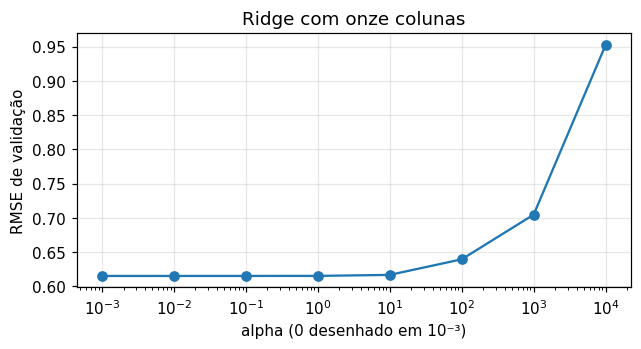

In [7]:
X11 = df[COUNT_FEATURES].to_numpy(dtype=float)
rows = []
for alpha in ALPHAS:
    fold_scores = []
    for train, valid in folds:
        model = model_for(alpha).fit(X11[train], y[train])
        fold_scores.append(clipped_rmse(y[valid], model.predict(X11[valid])))
    rows.append({'alpha': alpha, 'RMSE validação médio': np.mean(fold_scores)})
ridge = pd.DataFrame(rows)
display(ridge.round(6))

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(ridge['alpha'].replace(0, 1e-3), ridge['RMSE validação médio'], 'o-')
ax.set_xscale('log')
ax.set(xlabel='alpha (0 desenhado em 10⁻³)', ylabel='RMSE de validação', title='Ridge com onze colunas')
plt.show()

**Leitura:** o erro só piora quando `alpha` cresce. Com 3200 linhas de treino e 11 colunas, a regressão já tem variância baixa (gap ≈ 0,003). A penalização serve para reduzir variância, então aqui ela só acrescenta **viés**. O problema da regressão é viés, não variância.

## 6. O que ainda sobra nos resíduos do modelo final

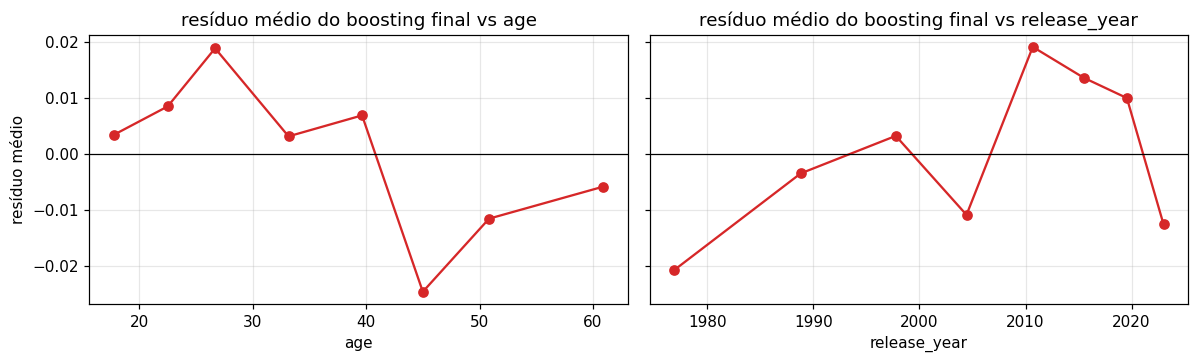

In [8]:
oof_boost = np.nanmean(predictions_11['Boosting'], axis=0)  # média das 5 repetições, só para o gráfico
residual = y - oof_boost
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, column in zip(axes, ['age', 'release_year']):
    bins = pd.qcut(df[column], 8)
    grouped = pd.DataFrame({'x': df[column], 'r': residual}).groupby(bins, observed=True).mean()
    ax.plot(grouped['x'], grouped['r'], 'o-', color='C3')
    ax.axhline(0, color='k', lw=0.8)
    ax.set(xlabel=column, title=f'resíduo médio do boosting final vs {column}')
axes[0].set_ylabel('resíduo médio')
plt.tight_layout()
plt.show()

**Leitura:** com idade e ano incluídos, os padrões marginais quase desaparecem. Mas ausência de padrão **marginal** não exclui uma **interação**. O experimento 8 (notebook 12) mostra que a combinação idade × ano (a idade do usuário no lançamento do filme) ainda guarda informação importante.

## 7. Modelo final e submissão

A receita foi congelada antes da submissão: **boosting com as onze colunas**. `src/final_submission.py`:
1. constrói as onze colunas no treino e no teste com a mesma função (`add_features`), que não aprende nada com os dados;
2. escolhe os hiperparâmetros com 3 dobras internas nas **4000 linhas** de treino;
3. reajusta o modelo nas 4000 linhas, prevê as 2000 linhas do teste e corta em [0, 5];
4. confere a ordem dos `pair_id`, os valores finitos e o número de linhas.

O teste não tem as notas e não foi usado para escolher nada.

hiperparâmetros escolhidos: {'l2_regularization': 0.0, 'max_leaf_nodes': 15, 'min_samples_leaf': 60}
linhas: 2000 | previsões entre 0.403 e 5.0


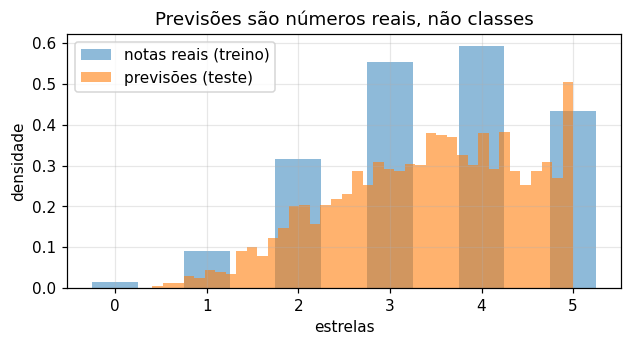

In [9]:
import json
submission = pd.read_csv(ROOT / 'submissions' / 'submission_final.csv')
metadata = json.loads((ROOT / 'submissions' / 'submission_final.json').read_text(encoding='utf-8'))
print('hiperparâmetros escolhidos:', metadata['selected_params'])
print('linhas:', len(submission), '| previsões entre', submission['stars'].min().round(3), 'e', submission['stars'].max().round(3))

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.hist(y, bins=np.arange(-0.25, 5.5, 0.5), alpha=0.5, density=True, label='notas reais (treino)')
ax.hist(submission['stars'], bins=40, alpha=0.6, density=True, label='previsões (teste)')
ax.set(xlabel='estrelas', ylabel='densidade', title='Previsões são números reais, não classes')
ax.legend()
plt.show()

**Leitura:** as previsões se concentram entre 2 e 5 e são mais "encolhidas" para o centro do que as notas reais. É o esperado ao minimizar o erro quadrático: o modelo prevê a **média condicional** da nota, que é um número real, e não chuta notas extremas quando há incerteza.

## Registro reproduzível desta execução

In [10]:
from src.current_results import save_run
predictions = {f'{name} 9 colunas': predictions_9[name] for name in predictions_9}
predictions.update({f'{name} 11 colunas': predictions_11[name] for name in predictions_11})
by_fold = pd.concat([
    by_fold_9.assign(modelo=by_fold_9['modelo'] + ' 9 colunas'),
    by_fold_11.assign(modelo=by_fold_11['modelo'] + ' 11 colunas'),
])
save_run(ROOT, '10_testes_finais', df, y, predictions, by_fold,
         N_SPLITS, N_REPEATS, SEED, CLIP)

Resultados verificados e salvos em /Users/mrm/Documents/Disciplinas/Apredizagem Estatística/movie-rating-prediction/results/rodada_atual/10_testes_finais.json


## Leitura da execução

Execução de 22 de novembro de 2026 (macOS, Python 3.9.6, scikit-learn 1.6.1).

| Modelo | RMSE OOF repetido | Gap treino–validação |
|---|---:|---:|
| Regressão, 6 colunas (referência, notebook 06) | 0,625036 | 0,001 |
| Regressão, 9 colunas | 0,616080 | 0,002 |
| Boosting, 9 colunas | 0,565157 | 0,109 |
| Regressão, 11 colunas | 0,615210 | 0,003 |
| Ridge, 11 colunas | 0,615210 | 0,003 |
| **Boosting, 11 colunas (receita final)** | **0,544933** | 0,113 |

- O boosting com onze colunas venceu a regressão nas 25 partições: diferença de −0,070, IC de 95% [−0,082; −0,059] no teste corrigido.
- As contagens melhoram o boosting nas 25 partições (−0,020), mas não a regressão de forma clara (−0,0009, p = 0,17).
- Ridge não traz ganho: a regressão já tem variância baixa, e o erro restante é de viés.

**Diferença em relação aos arquivos dos scripts.** Os CSVs em `results/rodada_atual` (`testes_contagens.csv` e `comparacao_final_procedimentos.csv`) foram gerados em outro computador e registram o boosting com 0,544851 (11 colunas) e 0,564180 (9 colunas). Aqui obtemos 0,544933 e 0,565157, de forma idêntica em execuções repetidas. A regressão e o Ridge coincidem em todas as casas. A diferença vem da busca interna do boosting: algumas configurações da grade empatam quase exatamente, e diferenças mínimas de arredondamento entre sistemas mudam a escolha em algumas partições. O efeito é inferior a 0,001 estrela e não muda nenhuma conclusão.